# Task 4 — Weather API & Time-Series EDA

## 0. Setup
Importing libraries

In [74]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["figure.dpi"] = 100


REGION_NAME = "Alexandria, Egypt"
LAT, LON    = 31.2001, 29.9187          # Alexandria city centre
START, END  = "20210101", "20251231"    # 5 full years, daily
PARAMETERS  = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR", "RH2M", "WS2M", "CLOUD_AMT"]
COMMUNITY   = "AG"

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
RAW_PATH   = DATA_DIR / "nasa_power_alexandria_raw.json"
CLEAN_PATH = DATA_DIR / "alexandria_weather_clean.csv"

#Find and Query a Weather API



In [75]:
BASE_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": ",".join(PARAMETERS),
    "community":  COMMUNITY,
    "longitude":  LON,
    "latitude":   LAT,
    "start":      START,
    "end":        END,
    "format":     "JSON",
}

def fetch_nasa_power(url, params, retries=4, backoff=5):
    # Call the API with retries. Handles HTTP 429 (rate limit) and transient errors.
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, params=params, timeout=120)
            print(f"[attempt {attempt}] HTTP {r.status_code}  ->  {r.url}")
            if r.status_code == 429:                     # rate limited
                wait = backoff * attempt
                print(f"   Rate limit hit (429). Waiting {wait}s ...")
                time.sleep(wait); continue
            r.raise_for_status()
            return r.json()
        except requests.exceptions.RequestException as e:
            print(f"   Request failed: {e}")
            time.sleep(backoff * attempt)
    raise RuntimeError("API call failed after all retries")

# Cache: only hit the API if we don't already have the raw file (saves quota + reproducible)
if RAW_PATH.exists():
    print(f"Raw file found, loading from disk: {RAW_PATH}")
    raw = json.loads(RAW_PATH.read_text())
else:
    raw = fetch_nasa_power(BASE_URL, params)
    RAW_PATH.write_text(json.dumps(raw))
    print(f"Raw response saved to {RAW_PATH}")

print("\nTop-level keys:", list(raw.keys()))
print("Fill value used for missing data:", raw.get("header", {}).get("fill_value"))
print("Parameters returned:", list(raw["properties"]["parameter"].keys()))

Raw file found, loading from disk: data/nasa_power_alexandria_raw.json

Top-level keys: ['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times']
Fill value used for missing data: -999.0
Parameters returned: ['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'WS2M', 'CLOUD_AMT']


### Confirm the endpoint returned data for our region


In [76]:
coords = raw["geometry"]["coordinates"]
print(f"Coordinates returned (lon, lat, elev): {coords}")
n_days = len(next(iter(raw["properties"]["parameter"].values())))
print(f"Days returned: {n_days}  (expected {(pd.Timestamp(END)-pd.Timestamp(START)).days+1})")

Coordinates returned (lon, lat, elev): [29.919, 31.2, 8.6]
Days returned: 1826  (expected 1826)


### Convert the raw JSON into a table


In [77]:
param_dict = raw["properties"]["parameter"]
df_raw = pd.DataFrame(param_dict)                  # index = 'YYYYMMDD' strings
df_raw.index.name = "date"
df_raw = df_raw.reset_index()

rename = {
    "T2M": "temperature", "T2M_MAX": "temp_max", "T2M_MIN": "temp_min",
    "PRECTOTCORR": "precipitation", "RH2M": "humidity",
    "WS2M": "wind_speed", "CLOUD_AMT": "cloud_cover",
}
df_raw = df_raw.rename(columns=rename)
df_raw.head()

,date,temperature,temp_max,temp_min,precipitation,humidity,wind_speed,cloud_cover
0,20210101,16.61,21.28,13.44,0.0,71.51,2.41,34.00
1,20210102,17.10,21.77,13.56,0.0,76.06,2.57,62.54
2,20210103,17.25,22.67,13.85,0.0,81.02,2.51,21.14
3,20210104,17.25,22.45,13.60,0.0,80.47,1.76,54.77
4,20210105,17.84,23.25,14.76,0.0,83.66,1.76,38.02


# Part 2 — Prepare the Time-Series Dataset

### Parse dates and set the datetime index
Dates currently look like 20210101 (a string). A **proper DatetimeIndex** is what unlocks resampling, rolling windows, seasonal decomposition, etc.

In [78]:
df = df_raw.copy()
df["date"] = pd.to_datetime(df["date"], format="%Y%m%d")
df = df.set_index("date").sort_index()
print(type(df.index), "| dtype:", df.index.dtype)
df.head(3)

<class 'pandas.core.indexes.datetimes.DatetimeIndex'> | dtype: datetime64[ns]


,temperature,temp_max,temp_min,precipitation,humidity,wind_speed,cloud_cover
date,,,,,,,
2021-01-01,16.61,21.28,13.44,0.0,71.51,2.41,34.00
2021-01-02,17.10,21.77,13.56,0.0,76.06,2.57,62.54
2021-01-03,17.25,22.67,13.85,0.0,81.02,2.51,21.14


### Replace the API's missing-value flag
NASA POWER uses **`-999`** for "no data". If we left it in, it would look like a real temperature of −999 °C and wreck every statistic. We convert it to NaN .

In [79]:
n_fill = (df == -999).sum()
print("Count of -999 fill values per column:\n", n_fill, "\n")
df = df.replace(-999, np.nan)

Count of -999 fill values per column:
 temperature      0
temp_max         0
temp_min         0
precipitation    0
humidity         0
wind_speed       0
cloud_cover      0
dtype: int64 



###Sampling frequency, gaps and duplicates
Three checks:
1. **Duplicate timestamps** → index.duplicated()
2. **Gaps** → compare against a complete daily range built with pd.date_range
3. **Frequency** → pd.infer_freq

In [80]:
dups = df.index.duplicated().sum()
full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
missing_dates = full_range.difference(df.index)

print(f"Rows: {len(df)} | Expected daily rows: {len(full_range)}")
print(f"Duplicated timestamps: {dups}")
print(f"Missing dates (gaps in the index): {len(missing_dates)}")
print("Inferred frequency:", pd.infer_freq(df.index))

# This inserts NaN rows for any missing dates
df = df.asfreq("D")
print("Index frequency after asfreq:", df.index.freq)

Rows: 1826 | Expected daily rows: 1826
Duplicated timestamps: 0
Missing dates (gaps in the index): 0
Inferred frequency: D
Index frequency after asfreq: <Day>


###Missing values
We **count and show** missing values before choosing a strategy.

In [81]:
miss = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct":   (df.isna().mean() * 100).round(2),
})
miss

,missing_count,missing_pct
temperature,0,0.0
temp_max,0,0.0
temp_min,0,0.0
precipitation,0,0.0
humidity,0,0.0
wind_speed,0,0.0
cloud_cover,0,0.0


In [82]:
# Visual check: where (in time) are values missing?
if df.isna().any().any():
    fig, ax = plt.subplots(figsize=(12, 3))
    sns.heatmap(df.isna().T, cbar=False, ax=ax, xticklabels=False)
    ax.set_title("Missing-value map (light = missing)"); ax.set_xlabel("Time"); plt.show()
else:
    print("No missing values after replacing -999 -> NaN. Nothing to visualise.")

No missing values after replacing -999 -> NaN. Nothing to visualise.


In [83]:
smooth_cols = [c for c in df.columns if c != "precipitation"]
before = df.isna().sum().sum()
df[smooth_cols] = df[smooth_cols].interpolate(method="time", limit=3, limit_direction="both")
after = df.isna().sum().sum()
print(f"Missing cells before: {before} | after: {after}")
print("Remaining missing per column:\n", df.isna().sum())

Missing cells before: 0 | after: 0
Remaining missing per column:
 temperature      0
temp_max         0
temp_min         0
precipitation    0
humidity         0
wind_speed       0
cloud_cover      0
dtype: int64


###Units and sanity checks
Units are known from the API documentation (**°C, mm/day, %, m/s**) and are consistent across the whole series because they all come from one source/endpoint, so no conversion is needed. We still verify the values:
* min ≤ mean ≤ max temperature
* precipitation ≥ 0
* humidity and cloud cover within 0–100 %
* temperatures within a realistic range for Alexandria

In [84]:
checks = {
    "temp_min <= temperature <= temp_max violations": int(((df.temp_min > df.temperature) | (df.temperature > df.temp_max)).sum()),
    "negative precipitation": int((df.precipitation < 0).sum()),
    "humidity outside 0-100": int(((df.humidity < 0) | (df.humidity > 100)).sum()),
    "cloud_cover outside 0-100": int(((df.cloud_cover < 0) | (df.cloud_cover > 100)).sum()),
    "negative wind speed": int((df.wind_speed < 0).sum()),
    "temperature outside [-5, 50] C": int(((df.temperature < -5) | (df.temperature > 50)).sum()),
}
pd.Series(checks, name="count")

,count
temp_min <= temperature <= temp_max violations,0
negative precipitation,0
humidity outside 0-100,0
cloud_cover outside 0-100,0
negative wind speed,0
"temperature outside [-5, 50] C",0


###Save the cleaned dataset

In [85]:
df.to_csv(CLEAN_PATH, index_label="date")
print(f"Saved cleaned data -> {CLEAN_PATH}  shape={df.shape}")
df.head()

Saved cleaned data -> data/alexandria_weather_clean.csv  shape=(1826, 7)


,temperature,temp_max,temp_min,precipitation,humidity,wind_speed,cloud_cover
date,,,,,,,
2021-01-01,16.61,21.28,13.44,0.0,71.51,2.41,34.00
2021-01-02,17.10,21.77,13.56,0.0,76.06,2.57,62.54
2021-01-03,17.25,22.67,13.85,0.0,81.02,2.51,21.14
2021-01-04,17.25,22.45,13.60,0.0,80.47,1.76,54.77
2021-01-05,17.84,23.25,14.76,0.0,83.66,1.76,38.02


# Part 3 — Exploratory Data Analysis



In [86]:
df[["temperature", "temp_min", "temp_max", "precipitation", "humidity", "wind_speed", "cloud_cover"]].describe().round(2)

,temperature,temp_min,temp_max,precipitation,humidity,wind_speed,cloud_cover
count,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00,1826.00
mean,22.00,17.53,27.73,0.47,63.78,3.24,33.95
std,5.51,5.06,6.36,3.23,7.89,0.97,28.62
min,9.74,5.90,11.96,0.00,27.83,0.91,0.43
25%,16.90,13.07,22.10,0.00,59.58,2.57,7.73
50%,22.40,17.74,28.15,0.00,63.66,3.20,27.14
75%,27.29,22.28,33.30,0.04,68.40,3.80,55.65
max,33.83,27.10,42.92,111.64,88.24,7.98,99.80


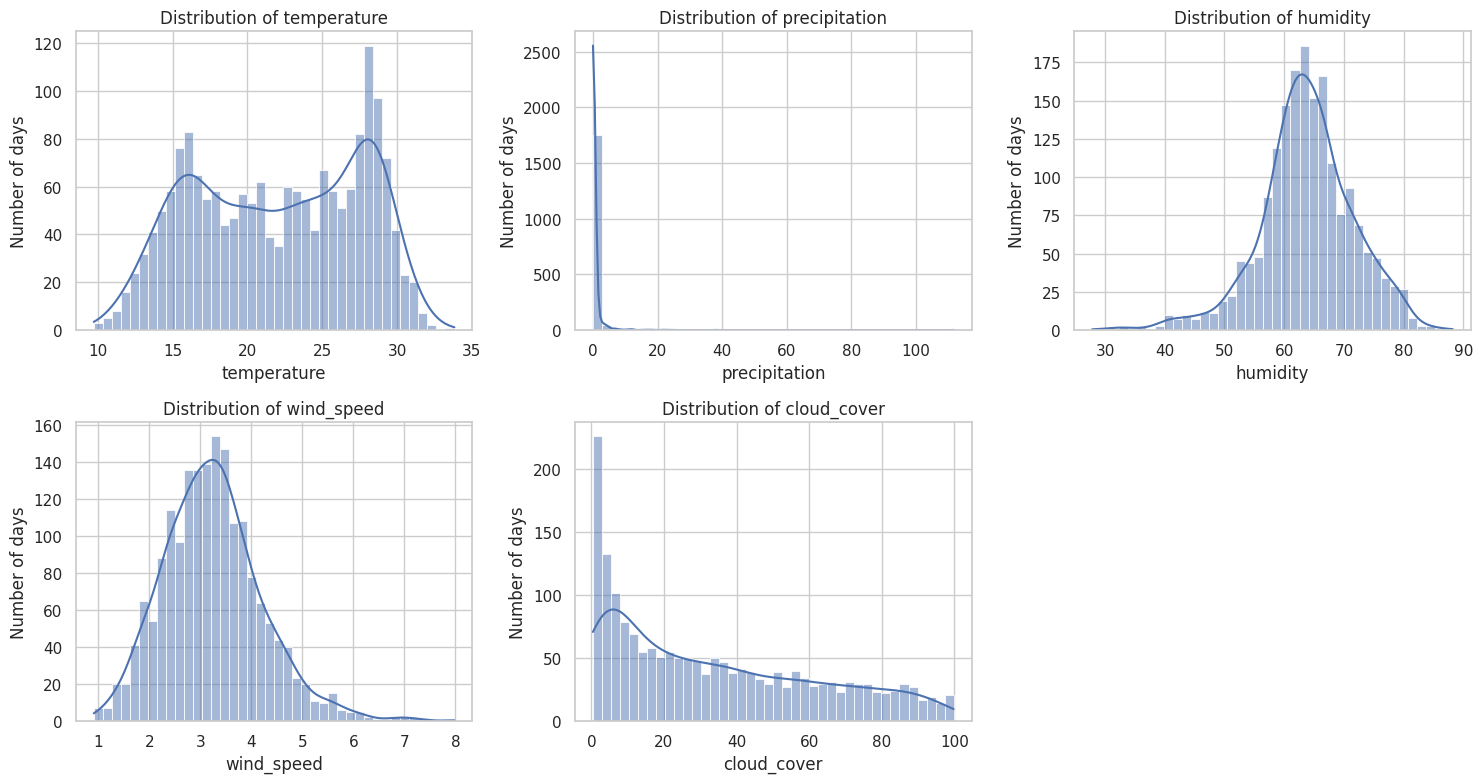

Share of days with < 0.1 mm precipitation: 79.3%
Skewness -> temperature: -0.12 | precipitation: 24.31


In [87]:
num_cols = ["temperature", "precipitation", "humidity", "wind_speed", "cloud_cover"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}"); ax.set_xlabel(col); ax.set_ylabel("Number of days")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# Extra: what share of days have (almost) no rain?
dry = (df.precipitation < 0.1).mean() * 100
print(f"Share of days with < 0.1 mm precipitation: {dry:.1f}%")
print(f"Skewness -> temperature: {df.temperature.skew():.2f} | precipitation: {df.precipitation.skew():.2f}")

**Interpretation guide**
* **Temperature** usually looks *bimodal / wide* (cool-season cluster + warm-season cluster) — a first hint of **seasonality**.
* **Precipitation** has a huge spike at 0 and a long right tail (high positive skew) → zero-inflated, non-normal.

## Temporal patterns


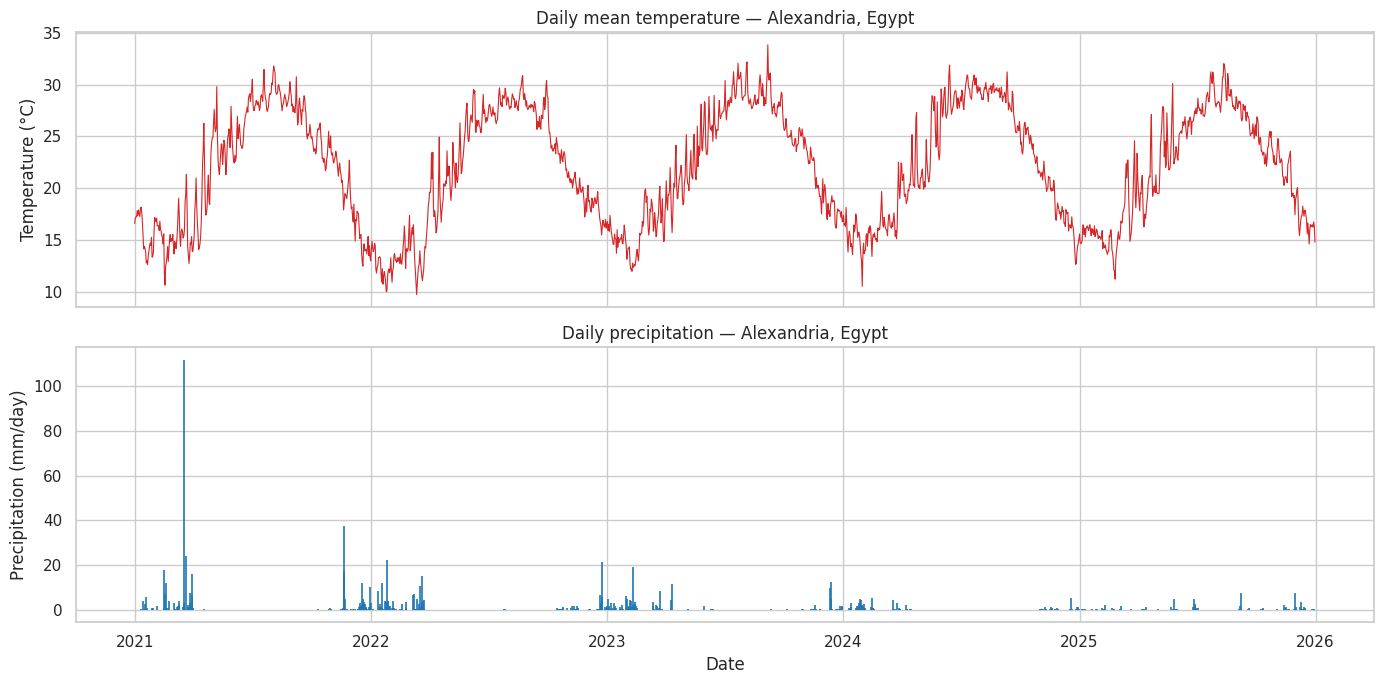

In [88]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(df.index, df.temperature, lw=0.8, color="tab:red")
axes[0].set_title(f"Daily mean temperature — {REGION_NAME}"); axes[0].set_ylabel("Temperature (°C)")

axes[1].vlines(df.index, 0, df.precipitation.fillna(0), color="tab:blue", lw=1.2)
axes[1].set_title(f"Daily precipitation — {REGION_NAME}"); axes[1].set_ylabel("Precipitation (mm/day)"); axes[1].set_xlabel("Date")
plt.tight_layout(); plt.show()

### Trend analysis (rolling mean)


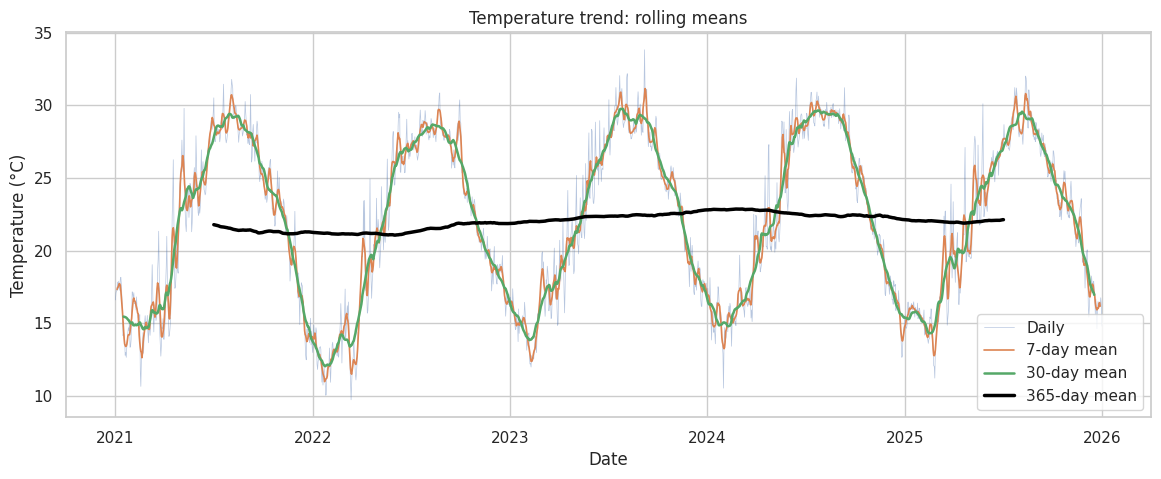

In [89]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df.temperature, lw=0.5, alpha=0.4, label="Daily")
ax.plot(df.index, df.temperature.rolling(7, center=True).mean(),   lw=1.2, label="7-day mean")
ax.plot(df.index, df.temperature.rolling(30, center=True).mean(),  lw=1.8, label="30-day mean")
ax.plot(df.index, df.temperature.rolling(365, center=True).mean(), lw=2.5, color="black", label="365-day mean")
ax.set_title("Temperature trend: rolling means"); ax.set_xlabel("Date"); ax.set_ylabel("Temperature (°C)"); ax.legend()
plt.show()

Trend in temperature anomaly: +0.177 °C per year  (p-value = 0.0000, R² = 0.0265)
=> Statistically significant trend


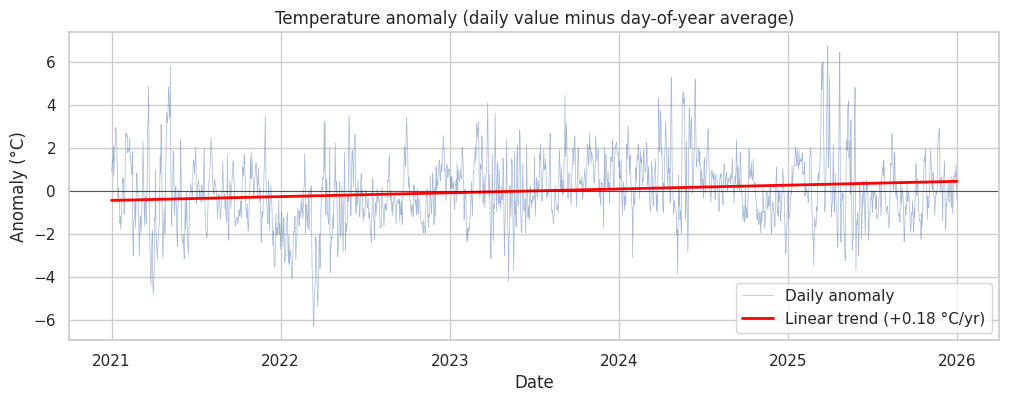

In [90]:
# Quantify the long-term trend with a linear regression on DESEASONALISED data.
# (Regressing raw temperature on time would be distorted by the seasonal cycle and where the series starts/ends in it.)
clim = df.temperature.groupby(df.index.dayofyear).transform("mean")
anomaly = (df.temperature - clim).dropna()

t_years = (anomaly.index - anomaly.index[0]).days / 365.25
slope, intercept, r, p, se = stats.linregress(t_years, anomaly.values)
print(f"Trend in temperature anomaly: {slope:+.3f} °C per year  (p-value = {p:.4f}, R² = {r**2:.4f})")
print("=> Statistically significant trend" if p < 0.05 else "=> No statistically significant linear trend at the 5% level")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(anomaly.index, anomaly, lw=0.5, alpha=0.5, label="Daily anomaly")
ax.plot(anomaly.index, intercept + slope * t_years, color="red", lw=2, label=f"Linear trend ({slope:+.2f} °C/yr)")
ax.axhline(0, color="k", lw=0.5)
ax.set_title("Temperature anomaly (daily value minus day-of-year average)"); ax.set_xlabel("Date"); ax.set_ylabel("Anomaly (°C)"); ax.legend()
plt.show()

**Caution when interpreting:** 5 years is a short window for *climate* trends (those need 30+ years). A small slope here may just reflect natural year-to-year variability.

### Seasonality — distributions by month

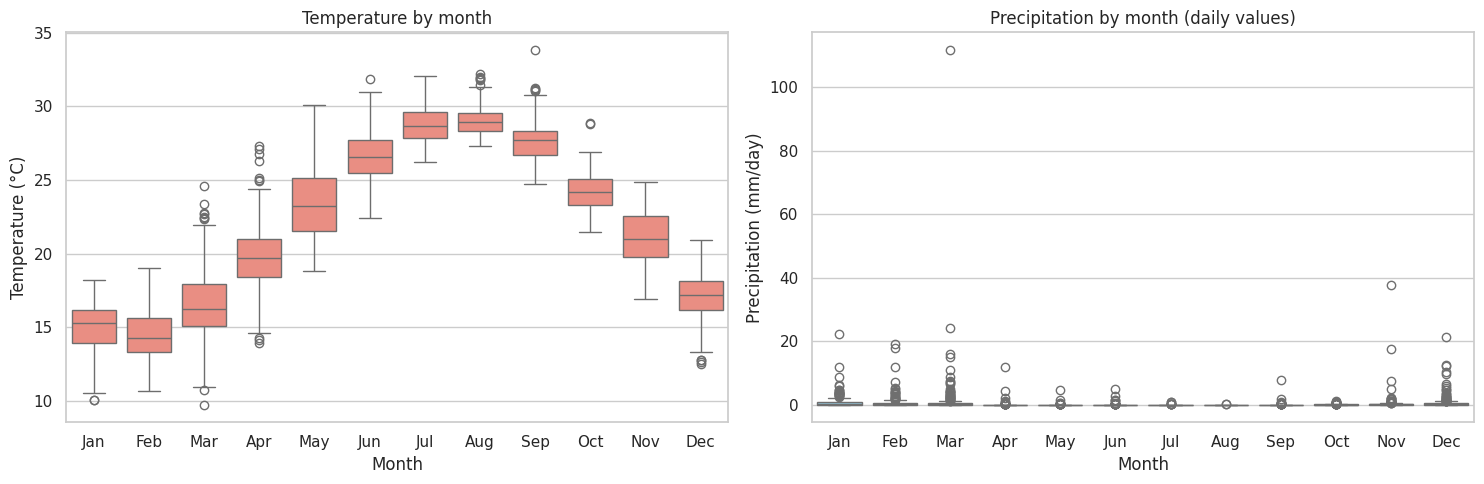

In [91]:
tmp = df.copy()
tmp["month"] = tmp.index.month
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=tmp, x="month", y="temperature", ax=axes[0], color="salmon")
axes[0].set_xticklabels(month_names); axes[0].set_title("Temperature by month"); axes[0].set_xlabel("Month"); axes[0].set_ylabel("Temperature (°C)")

sns.boxplot(data=tmp, x="month", y="precipitation", ax=axes[1], color="skyblue")
axes[1].set_xticklabels(month_names); axes[1].set_title("Precipitation by month (daily values)"); axes[1].set_xlabel("Month"); axes[1].set_ylabel("Precipitation (mm/day)")
plt.tight_layout(); plt.show()


**What to look for:** temperature should rise smoothly to a summer peak (Jul–Aug) and bottom out in winter (Jan–Feb). Rainfall should be concentrated in the winter months with near-zero in summer, a classic **Mediterranean climate** signature.

### Rolling statistics — local mean and volatility
The rolling **standard deviation** shows *local volatility*: periods when the weather swings more.

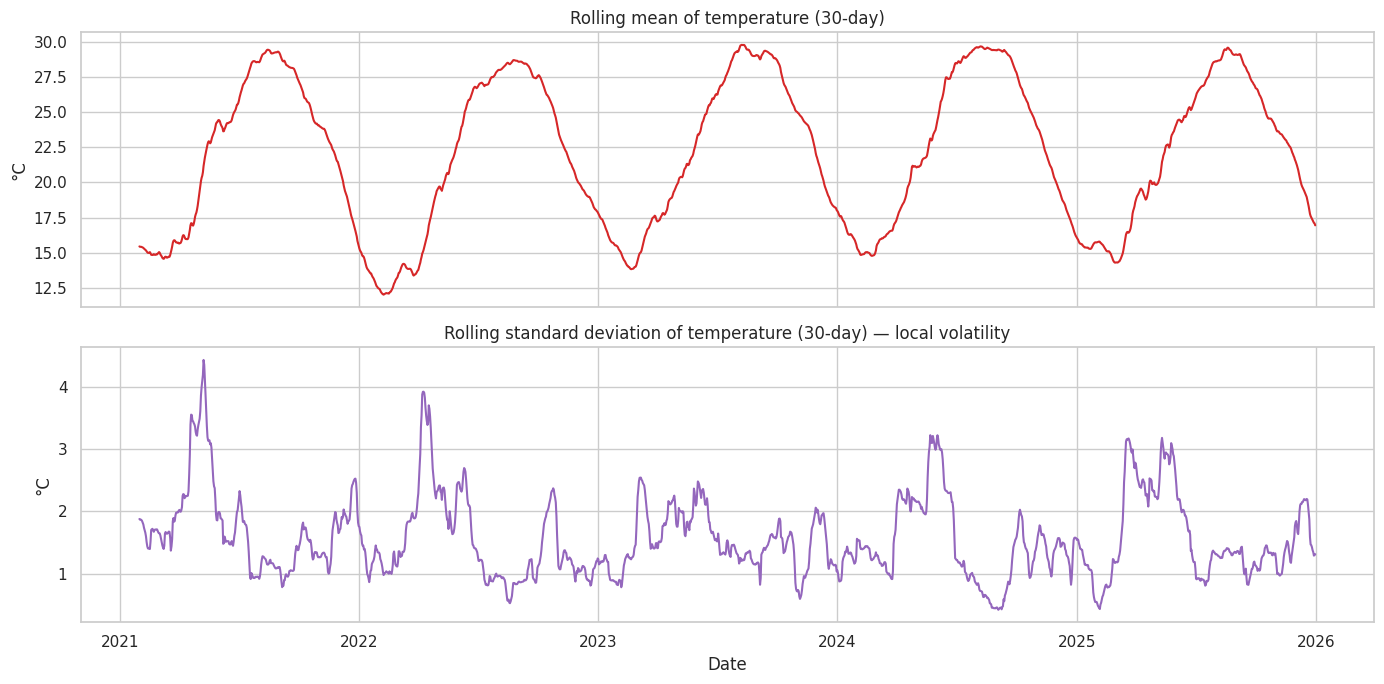

In [92]:
win = 30
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(df.index, df.temperature.rolling(win).mean(), color="tab:red")
axes[0].set_title(f"Rolling mean of temperature ({win}-day)"); axes[0].set_ylabel("°C")
axes[1].plot(df.index, df.temperature.rolling(win).std(), color="tab:purple")
axes[1].set_title(f"Rolling standard deviation of temperature ({win}-day) — local volatility"); axes[1].set_ylabel("°C"); axes[1].set_xlabel("Date")
plt.tight_layout(); plt.show()

##Decomposition and structure
### Decomposition into trend + seasonal + residual
We assume an **additive** model: series = trend + seasonal + residual. (Temperature in °C can be ≤ 0 in other climates, and the seasonal swing doesn't scale with the level, so additive is appropriate.)


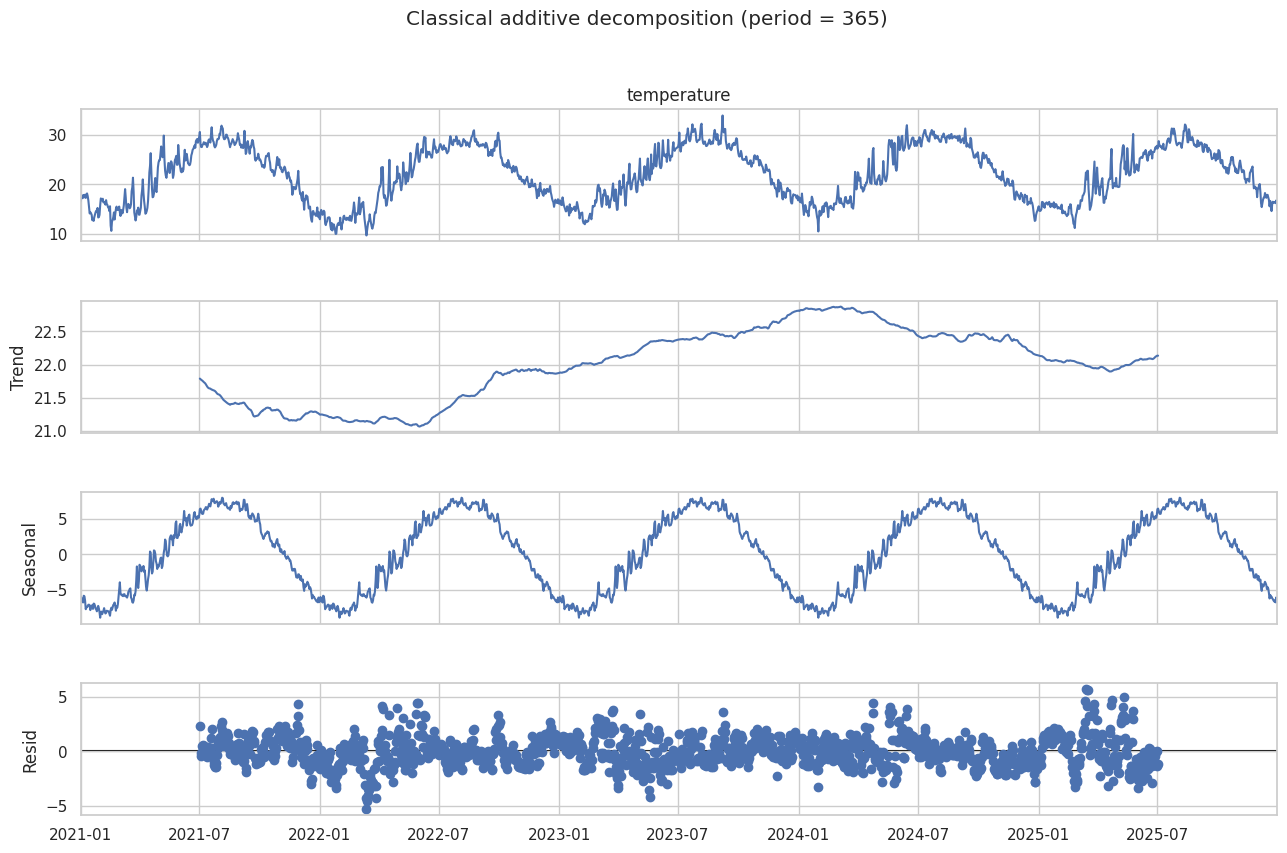

In [93]:
classic = seasonal_decompose(df["temperature"], model="additive", period=365)
fig = classic.plot(); fig.set_size_inches(13, 9)
fig.suptitle("Classical additive decomposition (period = 365)", y=1.01); plt.show()

**Reading the decomposition**
* **Trend:** slow movement of the average level.
* **Seasonal:** the repeating yearly pattern; its amplitude is the typical summer–winter swing.
* **Residual:** what's left (day-to-day weather). Ideally it looks like noise around 0; visible structure in it means the model missed something.

**Precipitation** is zero-inflated and intermittent, so a daily decomposition is not meaningful. We decompose **monthly rainfall totals** instead (period = 12).

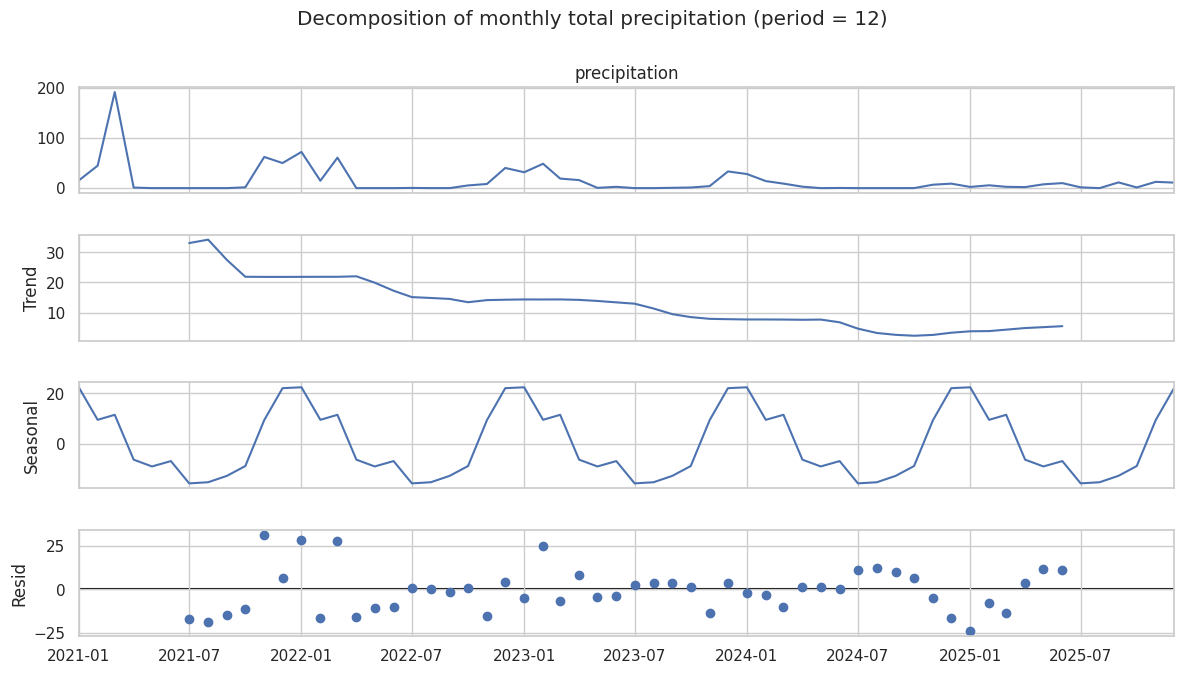

In [94]:
monthly_rain = df.precipitation.resample("MS").sum()
dec_rain = seasonal_decompose(monthly_rain, model="additive", period=12)
fig = dec_rain.plot(); fig.set_size_inches(12, 7)
fig.suptitle("Decomposition of monthly total precipitation (period = 12)", y=1.01); plt.show()

### Autocorrelation (ACF) and partial autocorrelation (PACF)
* **ACF**: correlation of the series with itself at lag *k* (includes indirect effects).
* **PACF**: correlation at lag *k* after removing the effect of lags 1…k-1 (direct effect only).
* Blue band = 95 % confidence band; bars outside it are statistically significant.

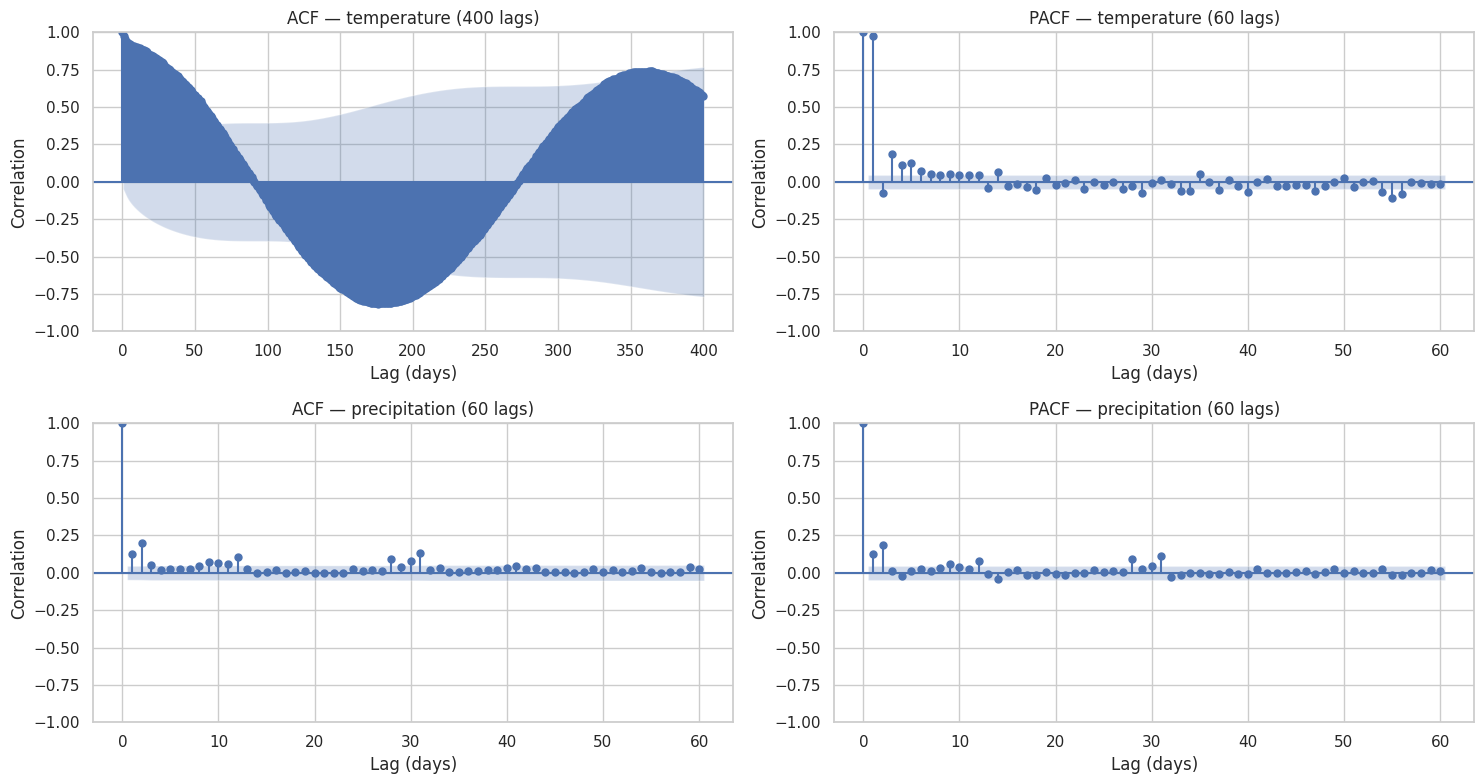

In [95]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_acf(df["temperature"],  lags=400, ax=axes[0, 0]);  axes[0, 0].set_title("ACF — temperature (400 lags)")
plot_pacf(df["temperature"], lags=60,  ax=axes[0, 1], method="ywm"); axes[0, 1].set_title("PACF — temperature (60 lags)")
plot_acf(df.precipitation.dropna(),  lags=60, ax=axes[1, 0]); axes[1, 0].set_title("ACF — precipitation (60 lags)")
plot_pacf(df.precipitation.dropna(), lags=60, ax=axes[1, 1], method="ywm"); axes[1, 1].set_title("PACF — precipitation (60 lags)")
for a in axes.ravel(): a.set_xlabel("Lag (days)"); a.set_ylabel("Correlation")
plt.tight_layout(); plt.show()

**Interpretation**
* **Temperature ACF** decays very slowly and swings up/down in a wave that repeats about every **365 lags** → strong **yearly seasonality** and long memory. The **PACF** is large at lag 1 (and a few more small lags): today's temperature is mostly explained by yesterday's → an autoregressive (AR) structure.
* **Precipitation ACF/PACF** drop quickly to near the confidence band: rain is only weakly dependent on previous days (short memory), apart from small clustering of wet spells.

### Stationarity tests
A series is **stationary** if its mean, variance and autocorrelation don't change over time.

In [96]:
def stationarity_report(s, name):
    s = s.dropna()
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, _, kpss_crit = kpss(s, regression="c", nlags="auto")
    adf_verdict  = "stationary" if adf_p < 0.05 else "NON-stationary"
    kpss_verdict = "stationary" if kpss_p >= 0.05 else "NON-stationary"
    return {"series": name,
            "ADF stat": round(adf_stat, 3), "ADF p": round(adf_p, 4), "ADF says": adf_verdict,
            "KPSS stat": round(kpss_stat, 3), "KPSS p": round(kpss_p, 4), "KPSS says": kpss_verdict}

deseason = df["temperature"] - classic.seasonal                         # remove seasonality only
diff1    = df["temperature"].diff().dropna()                        # first difference

results = pd.DataFrame([
    stationarity_report(df["temperature"],                  "Temperature (raw)"),
    stationarity_report(deseason,              "Temperature (seasonality removed)"),
    stationarity_report(diff1,                 "Temperature (1st difference)"),
    stationarity_report(df.precipitation,      "Precipitation (raw)"),
])
results

,series,ADF stat,ADF p,ADF says,KPSS stat,KPSS p,KPSS says
0,Temperature (raw),-2.258,0.186,NON-stationary,0.179,0.10,stationary
1,Temperature (seasonality removed),-7.919,0.000,stationary,1.050,0.01,NON-stationary
2,Temperature (1st difference),-15.946,0.000,stationary,0.060,0.10,stationary
3,Precipitation (raw),-9.239,0.000,stationary,0.925,0.01,NON-stationary


In [97]:
# Precipitation extremes: heavy rain is skewed, so look at the upper tail with a high quantile instead of z-score
p99 = df.precipitation.quantile(0.99)
heavy = df.precipitation[df.precipitation > p99].sort_values(ascending=False)
print(f"99th percentile of precipitation: {p99:.2f} mm/day -> {len(heavy)} days above it")
heavy.head(10)

99th percentile of precipitation: 8.56 mm/day -> 19 days above it


,precipitation
date,
2021-03-19,111.64
2021-11-20,37.62
2021-03-21,24.24
2022-01-26,22.27
2022-12-24,21.35
2023-02-11,19.20
2021-02-16,17.67
2021-11-21,17.34
2021-03-31,15.91


### Flag suspicious values (likely sensor / API errors vs real events)
A *real* extreme weather event is physically consistent across variables; an *error* is not. We test for **physically impossible** or **inconsistent** values and for **flat-lined** data (the same value repeated, which suggests a stuck sensor or filled data).

In [98]:
issues = {
    "Impossible: negative precipitation":            df.precipitation < 0,
    "Impossible: humidity/cloud outside 0-100":     (df.humidity.lt(0) | df.humidity.gt(100) | df.cloud_cover.lt(0) | df.cloud_cover.gt(100)),
    "Inconsistent: temp_min > temp_max":             df.temp_min > df.temp_max,
    "Inconsistent: mean outside [min, max]":        (df.temperature < df.temp_min) | (df.temperature > df.temp_max),
    "Implausible: |day-to-day change| > 10 °C":      df.temperature.diff().abs() > 10,
    "Suspicious: temperature identical for 5+ days": df.temperature.rolling(5).apply(lambda x: float(len(set(x)) == 1), raw=True).eq(1),
    "Rain on a day with very low humidity (<25%)":   (df.precipitation > 1) & (df.humidity < 25),
}
report = pd.Series({k: int(v.sum()) for k, v in issues.items()}, name="days flagged")
display(report.to_frame())

# Show a few examples for any check that fired
for name, mask in issues.items():
    if mask.sum() > 0:
        print(f"\n>>> {name}")
        display(df.loc[mask].head(5))

,days flagged
Impossible: negative precipitation,0
Impossible: humidity/cloud outside 0-100,0
Inconsistent: temp_min > temp_max,0
"Inconsistent: mean outside [min, max]",0
Implausible: |day-to-day change| > 10 °C,0
Suspicious: temperature identical for 5+ days,0
Rain on a day with very low humidity (<25%),0


**Decision rule used:** impossible/inconsistent values would be set to `NaN` (and then handled with the strategy from Part 2). Extreme-but-physically-consistent values (e.g. a heat wave with high temperature, low humidity and clear skies, or a storm with heavy rain, high cloud cover and high humidity) are **kept**: they are real weather, and removing them would bias any model.

In [99]:
# Calculate seasonality strength (Ft)
trend = classic.trend.dropna()
resid = classic.resid.dropna()
# Align trend and residual indices
valid_idx = trend.index.intersection(resid.index)
var_resid = resid.loc[valid_idx].var()
var_trend_resid = (trend.loc[valid_idx] + resid.loc[valid_idx]).var()
Ft = max(0, 1 - var_resid / var_trend_resid)

# Calculate outliers
z_scores = stats.zscore(df["temperature"].dropna())
out_z = df["temperature"].dropna()[abs(z_scores) > 3]

q25, q75 = resid.quantile(0.25), resid.quantile(0.75)
iqr = q75 - q25
out_iqr = resid[(resid < q25 - 1.5 * iqr) | (resid > q75 + 1.5 * iqr)]

adf_p_raw   = results.loc[0, "ADF p"];   kpss_p_raw = results.loc[0, "KPSS p"]
hottest = df.temperature.resample("MS").mean().groupby(lambda d: d.month).mean()
rain_by_month = df.precipitation.resample("MS").sum().groupby(lambda d: d.month).mean()
dry_season_rain = rain_by_month[[6, 7, 8]].sum()
wet_share = rain_by_month[[11, 12, 1, 2, 3]].sum() / rain_by_month.sum() * 100

print(f"Region / range : {REGION_NAME}, {df.index.min().date()} -> {df.index.max().date()} ({len(df)} daily rows)")
print(f"Warmest month  : {month_names[hottest.idxmax()-1]} ({hottest.max():.1f} °C) | Coolest: {month_names[hottest.idxmin()-1]} ({hottest.min():.1f} °C)")
print(f"Mean annual rainfall: {df.precipitation.resample('YS').sum().mean():.0f} mm | share falling Nov-Mar: {wet_share:.0f}%")
print(f"Trend (anomaly): {slope:+.3f} °C/yr (p={p:.3f})")
print(f"Seasonality strength: {Ft:.2f}")
print(f"Stationarity of raw temperature -> ADF p={adf_p_raw}, KPSS p={kpss_p_raw}")
print(f"Missing cells found/handled: {int(miss.missing_count.sum())} | -999 fills: {int(n_fill.sum())} | duplicates: {dups} | gaps: {len(missing_dates)}")
print(f"Outliers: {len(out_z)} (z-score), {len(out_iqr)} (STL-IQR) | Physical-impossibility flags: {int(report.iloc[:4].sum())}")

Region / range : Alexandria, Egypt, 2021-01-01 -> 2025-12-31 (1826 daily rows)
Warmest month  : Aug (29.1 °C) | Coolest: Feb (14.4 °C)
Mean annual rainfall: 173 mm | share falling Nov-Mar: 92%
Trend (anomaly): +0.177 °C/yr (p=0.000)
Seasonality strength: 0.13
Stationarity of raw temperature -> ADF p=0.186, KPSS p=0.1
Missing cells found/handled: 0 | -999 fills: 0 | duplicates: 0 | gaps: 0
Outliers: 0 (z-score), 34 (STL-IQR) | Physical-impossibility flags: 0
